Précision interne avant apprentissage : 9.6%
Boucle d'apprentissage 1/5 en cours... Précision interne : 83.3%
Boucle d'apprentissage 2/5 en cours... Précision interne : 91.5%
Boucle d'apprentissage 3/5 en cours... Précision interne : 93.0%
Boucle d'apprentissage 4/5 en cours... Précision interne : 93.10000000000001%
Boucle d'apprentissage 5/5 en cours... Précision interne : 94.3%
Precision des tests : 94.24
Précision interne avant apprentissage : 9.3%
Boucle d'apprentissage 1/5 en cours... Précision interne : 93.4%
Boucle d'apprentissage 2/5 en cours... Précision interne : 94.69999999999999%
Boucle d'apprentissage 3/5 en cours... Précision interne : 95.1%
Boucle d'apprentissage 4/5 en cours... Précision interne : 96.1%
Boucle d'apprentissage 5/5 en cours... Précision interne : 96.2%
Precision des tests : 95.81
Précision interne avant apprentissage : 10.2%
Boucle d'apprentissage 1/5 en cours... Précision interne : 96.89999999999999%
Boucle d'apprentissage 2/5 en cours... Précision inter

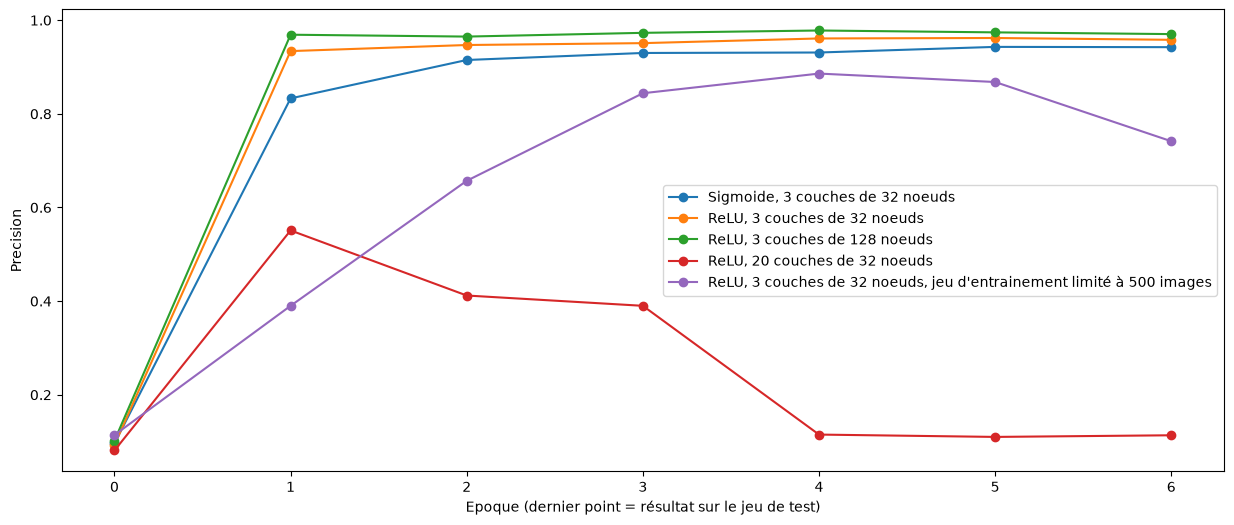

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import images
from models import Sequential


list_train_image_x = images.load_mnist_idx("train-images.idx3-ubyte")
list_train_image_y = images.load_mnist_idx("train-labels.idx1-ubyte")
X_train = list_train_image_x.copy()/255
Y_train = np.eye(10)[list_train_image_y]

X_train_small = X_train[:500]
Y_train_small = Y_train[:500]


list_test_image_x = images.load_mnist_idx("t10k-images.idx3-ubyte")
X_test = list_test_image_x.copy()/255
Y_test = images.load_mnist_idx("t10k-labels.idx1-ubyte")

N2 = list_test_image_x.shape[0]


hp = [[32, 3, "sigmoid", 5], [32, 3, "relu", 5], [128, 3, "relu", 5], [32, 20, "relu", 5], [32, 3, "relu", 5] ]
#hp = [[32, 3, "relu", 5]]
precisions_internes_test = []


for i in range(len(hp)):
    model = Sequential(hp[i][0], hp[i][1], hp[i][2],hp[i][3], 0.01)
    
    if(i != len(hp)-1):
        precisions = model.fit(X_train, Y_train)
    else: 
        precisions = model.fit(X_train_small, Y_train_small)
        print("Surapprentissage volontaire")
    right_ones = 0

    value_list = [0.0 for _ in range(10)]
    for i in range(N2):
        x = model.predict([X_test[i]])
        value_list[np.argmax(x[0])] += 1
        if  np.argmax(x[0]) == Y_test[i]:
            right_ones += 1
    print(f"Precision des tests : {(right_ones*100)/N2}")        
    #Ajout de la précision du jeu de test
    precisions.append(right_ones/N2)
    precisions_internes_test.append(precisions)

abscisses = [i for i in range(len(precisions_internes_test[0]))]

plt.figure(figsize=(15, 6))
plt.plot(abscisses, precisions_internes_test[0], "o-", label="Sigmoide, 3 couches de 32 noeuds")
plt.plot(abscisses, precisions_internes_test[1], "o-", label="ReLU, 3 couches de 32 noeuds")
plt.plot(abscisses, precisions_internes_test[2], "o-", label="ReLU, 3 couches de 128 noeuds")
plt.plot(abscisses, precisions_internes_test[3], "o-", label="ReLU, 20 couches de 32 noeuds")
plt.plot(abscisses, precisions_internes_test[4], "o-", label="ReLU, 3 couches de 32 noeuds, jeu d'entrainement limité à 500 images")
plt.xlabel("Epoque (dernier point = résultat sur le jeu de test)")
plt.ylabel("Precision")
plt.legend()
plt.savefig("courbes_apprentissage.png", dpi=150)


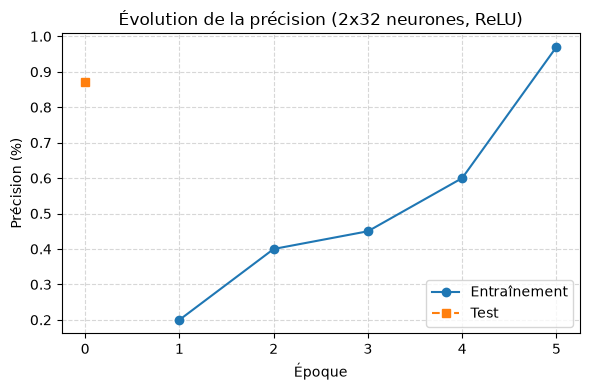

In [4]:
import numpy as np
import matplotlib.pyplot as plt


# 2. Courbe d'apprentissage (listes des précisions à chaque époque)
epochs = [1, 2, 3, 4, 5]
acc_train = [0.2, 0.4, 0.45 ,0.6, 0.97]
acc_test = [0.87]
plt.figure(figsize=(6, 4))
plt.plot(epochs, acc_train, 'o-', label="Entraînement")
plt.plot( acc_test, 's--', label="Test")
plt.title("Évolution de la précision (2x32 neurones, ReLU)")
plt.xlabel("Époque")
plt.ylabel("Précision (%)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
#plt.savefig("courbe_apprentissage.png", dpi=150)